# Imports de bibliotecas

In [86]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

### Import dos dados e exploração

In [87]:
df = pd.read_csv('personal_transactions.csv')
df.Date = pd.to_datetime(df.Date)


In [88]:
df.head()

,Date,Description,Amount,Transaction Type,Category,Account Name
0,2018-01-01,Amazon,11.11,debit,Shopping,Platinum Card
1,2018-01-02,Mortgage Payment,1247.44,debit,Mortgage & Rent,Checking
2,2018-01-02,Thai Restaurant,24.22,debit,Restaurants,Silver Card
3,2018-01-03,Credit Card Payment,2298.09,credit,Credit Card Payment,Platinum Card
4,2018-01-04,Netflix,11.76,debit,Movies & DVDs,Platinum Card


In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 806 entries, 0 to 805
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              806 non-null    datetime64[ns]
 1   Description       806 non-null    object        
 2   Amount            806 non-null    float64       
 3   Transaction Type  806 non-null    object        
 4   Category          806 non-null    object        
 5   Account Name      806 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(4)
memory usage: 37.9+ KB


In [90]:

df['Date'] = pd.to_datetime(df['Date'])

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day
df['Day_of_Week'] = df['Date'].dt.dayofweek

monthly_df = df.groupby(df['Date'].dt.to_period('M')).sum(numeric_only=True).reset_index()

from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df['Transaction_Type_Encoded'] = encoder.fit_transform(df['Transaction Type'])
df['Category_Encoded'] = encoder.fit_transform(df['Category'])
df['Account_Name_Encoded'] = encoder.fit_transform(df['Account Name'])

expenses = df[df['Transaction Type'] == 'debit']

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df['Normalized_Amount'] = scaler.fit_transform(df[['Amount']])

df['Rolling_3_Month_Avg'] = df['Amount'].rolling(window=3).mean()

df['Cumulative_Spend'] = df['Amount'].cumsum()

### Análise dos dados de gastos

In [91]:
debito = df[df["Transaction Type"] == 'debit']


In [92]:
gastos_by_cat = debito.groupby("Category", as_index=False)["Amount"].sum().sort_values("Amount", ascending=False)
gastos_by_cat["cum_perc"] = gastos_by_cat["Amount"].cumsum() / gastos_by_cat["Amount"].sum()

top_gastos = gastos_by_cat[gastos_by_cat["cum_perc"] <= 0.8]
outros_gastos = gastos_by_cat[gastos_by_cat["cum_perc"] > 0.8]
if not outros_gastos.empty:
    outros_row = pd.DataFrame({
        "Category": ["Outros"],
        "Amount": [outros_gastos["Amount"].sum()]
    })
    gastos_by_cat_pareto = pd.concat([top_gastos[["Category", "Amount"]], outros_row], ignore_index=True)
else:
    gastos_by_cat_pareto = gastos_by_cat[["Category", "Amount"]]

qtde_categorias = debito.groupby("Category", as_index=False)["Amount"].count().sort_values("Amount", ascending=False)
qtde_categorias["cum_perc"] = qtde_categorias["Amount"].cumsum() / qtde_categorias["Amount"].sum()

top_qtde = qtde_categorias[qtde_categorias["cum_perc"] <= 0.8]
outros_qtde = qtde_categorias[qtde_categorias["cum_perc"] > 0.8]
if not outros_qtde.empty:
    outros_row_qtde = pd.DataFrame({
        "Category": ["Outros"],
        "Amount": [outros_qtde["Amount"].sum()]
    })
    qtde_categorias_pareto = pd.concat([top_qtde[["Category", "Amount"]], outros_row_qtde], ignore_index=True)
else:
    qtde_categorias_pareto = qtde_categorias[["Category", "Amount"]]

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type':'domain'}, {'type':'domain'}]],
    subplot_titles=["Distribuição de gastos por categoria (Pareto)", "Distribuição de quantidade por categoria (Pareto)"]
)

fig.add_trace(
    go.Pie(
        labels=gastos_by_cat_pareto["Category"],
        values=gastos_by_cat_pareto["Amount"],
        hole=0.4,
        name="Gastos"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Pie(
        labels=qtde_categorias_pareto["Category"],
        values=qtde_categorias_pareto["Amount"],
        hole=0.4,
        name="Quantidade"
    ),
    row=1, col=2
)

fig.update_layout(title_text="Gastos e Quantidade de Transações por Categoria (Pareto)", showlegend=True)
fig.show()

Foi utilizado paretto para agrupar as categorias, pois haviam muitas categorias, causando confusão e dificultando a análise. 
Nota-se que há um gasto bem grande com groceries e restaurantes 27% de todos os gastos. Sendo recomendado diminuir esses gastos, estipular uma meta e ir acompanhando ao decorrer do tempo se está sendo cumprida.

In [93]:
qtde_categorias = debito.groupby("Account Name", as_index=False)["Amount"].count()

soma_categorias = debito.groupby("Account Name", as_index=False)["Amount"].sum()

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type':'domain'}, {'type':'domain'}]],
    subplot_titles=["Distribuição de quantidade por Conta", "Distribuição de entradas por Conta"]
)

fig.add_trace(
    go.Pie(
        labels=qtde_categorias["Account Name"],
        values=qtde_categorias["Amount"],
        hole=0.4,
        name="Quantidade"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Pie(
        labels=soma_categorias["Account Name"],
        values=soma_categorias["Amount"],
        hole=0.4,
        name="Entradas"
    ),
    row=1, col=2
)

fig.update_layout(title_text="Despesas em Quantidade e Entradas por Conta", showlegend=True)
fig.show()

Maioria dos gastos estão concentrados em checking se observarmos por valor, onde mesmo Platinum card tendo maior quantidade só representa 9% do valor dos gastos

### Análise de Entradas

In [94]:
credits = df[df["Transaction Type"] == 'credit']
credits.head()

,Date,Description,Amount,Transaction Type,Category,Account Name,Year,Month,Day,Day_of_Week,Transaction_Type_Encoded,Category_Encoded,Account_Name_Encoded,Normalized_Amount,Rolling_3_Month_Avg,Cumulative_Spend
3,2018-01-03,Credit Card Payment,2298.09,credit,Credit Card Payment,Platinum Card,2018,1,3,2,0,3,1,0.249650,1189.916667,3580.86
13,2018-01-12,Biweekly Paycheck,2000.00,credit,Paycheck,Checking,2018,1,12,4,0,17,0,0.217242,692.803333,5875.86
20,2018-01-19,Biweekly Paycheck,2000.00,credit,Paycheck,Checking,2018,1,19,4,0,17,0,0.217242,698.333333,8151.12
22,2018-01-22,Credit Card Payment,554.99,credit,Credit Card Payment,Platinum Card,2018,1,22,0,0,3,1,0.060146,868.400000,8756.32
23,2018-01-22,Credit Card Payment,309.81,credit,Credit Card Payment,Silver Card,2018,1,22,0,0,3,2,0.033491,305.003333,9066.13


In [95]:
qtde_categorias = credits.groupby("Account Name", as_index=False)["Amount"].count()

soma_categorias = credits.groupby("Account Name", as_index=False)["Amount"].sum()

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type':'domain'}, {'type':'domain'}]],
    subplot_titles=["Distribuição de quantidade por Conta", "Distribuição de entradas por Conta"]
)

fig.add_trace(
    go.Pie(
        labels=qtde_categorias["Account Name"],
        values=qtde_categorias["Amount"],
        hole=0.4,
        name="Quantidade"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Pie(
        labels=soma_categorias["Account Name"],
        values=soma_categorias["Amount"],
        hole=0.4,
        name="Entradas"
    ),
    row=1, col=2
)

fig.update_layout(title_text="Receita em Quantidade e Entradas por Conta", showlegend=True)
fig.show()

Nota-se boa distribuição da quantidade de entradas por conta, sendo possível que sempre que o individuo recebe um valor ele realiza pagamentos dos seus cartões. Também é possível observar que mesmo tendo uma boa distribuição de quantidade, o montante financeiro gasto em cartões de crédito não significa mais do que 25% do valor.

In [107]:
qtde_mes = debito.groupby(["Year", "Month"], as_index=False)["Amount"].count()
soma_mes = debito.groupby(["Year", "Month"], as_index=False)["Amount"].sum()
qtde_mes["Date"] = pd.to_datetime(qtde_mes[["Year", "Month"]].assign(DAY=1))
soma_mes["Date"] = pd.to_datetime(soma_mes[["Year", "Month"]].assign(DAY=1))

fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=["Quantidade de transações por mês", "Soma dos gastos por mês"]
)

fig.add_trace(
    go.Scatter(
        x=qtde_mes["Date"],
        y=qtde_mes["Amount"],
        mode="lines+markers",
        name="Quantidade"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=soma_mes["Date"],
        y=soma_mes["Amount"],
        mode="lines+markers",
        name="Entradas"
    ),
    row=2, col=1
)

fig.update_layout(title_text="Gastos em Quantidade e Entradas por Mês", showlegend=True)
fig.show()

Observando a temporalidade dos dados, nota-se que há sazonalidade nos dados, sendo possível observar picos em datas próximas. Oque nos ajuda a aplicar modelos preditivos nos dados

In [110]:
qtde_mes = credits.groupby(["Year", "Month"], as_index=False)["Amount"].count()
soma_mes = credits.groupby(["Year", "Month"], as_index=False)["Amount"].sum()
qtde_mes["Date"] = pd.to_datetime(qtde_mes[["Year", "Month"]].assign(DAY=1))
soma_mes["Date"] = pd.to_datetime(soma_mes[["Year", "Month"]].assign(DAY=1))

fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=["Quantidade de transações por mês", "Soma dos Recebimentos por mês"]
)

fig.add_trace(
    go.Scatter(
        x=qtde_mes["Date"],
        y=qtde_mes["Amount"],
        mode="lines+markers",
        name="Quantidade"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=soma_mes["Date"],
        y=soma_mes["Amount"],
        mode="lines+markers",
        name="Entradas"
    ),
    row=2, col=1
)

fig.update_layout(title_text="Recebimentos em Quantidade e Entradas por Mês", showlegend=True)
fig.show()

In [109]:
df['YearMonth'] = df['Date'].dt.to_period('M')
saldos = df.pivot_table(
    index='YearMonth',
    columns='Transaction Type',
    values='Amount',
    aggfunc='sum',
    fill_value=0
).reset_index()

saldos['Saldo_Mes'] = saldos.get('credit', 0) - saldos.get('debit', 0)


saldos['Date'] = saldos['YearMonth'].dt.to_timestamp()

import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Bar(
    x=saldos['Date'],
    y=saldos['Saldo_Mes'],
    name='Saldo do Mês',
    marker_color='seagreen'
))
fig.add_trace(go.Scatter(
    x=saldos['Date'],
    y=saldos['Saldo_Mes'].cumsum(),
    name='Saldo Acumulado',
    mode='lines+markers',
    marker_color='royalblue'
))
fig.update_layout(
    title='Saldo Mensal e Acumulado',
    xaxis_title='Mês',
    yaxis_title='Saldo (Entradas - Saídas)',
    legend_title='Legenda'
)
fig.show()

Já o saldo mensal é percebido que ele é constante, havendo alguns desvios porém sempre aumentando


## Predição utilizando IA

2019-10     5723.482798
2019-11     6149.806012
2019-12     6331.126582
2020-01     6598.044876
2020-02     6835.057491
2020-03     7082.518393
2020-04     7326.328929
2020-05     7571.414810
2020-06     7816.055118
2020-07     8060.851097
2020-08     8305.592689
2020-09     8550.353283
2020-10     8795.107238
2020-11     9039.863512
2020-12     9284.618976
2021-01     9529.374723
2021-02     9774.130371
2021-03    10018.886054
2021-04    10263.641725
2021-05    10508.397400
2021-06    10753.153073
2021-07    10997.908747
2021-08    11242.664421
2021-09    11487.420094
Freq: M, Name: predicted_mean, dtype: float64


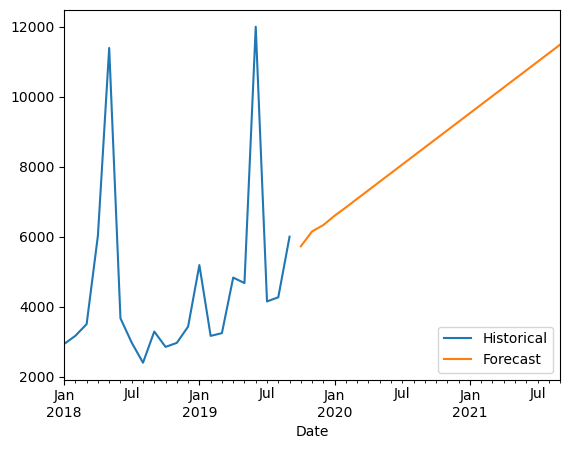

In [112]:
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

# Aggregating all monthly expenses
monthly_expenses = expenses.groupby(expenses['Date'].dt.to_period('M'))['Amount'].sum()

# Fit ARIMA model
# 1 is not better as it creates stationary data without changing based on trend
# tried 10 but produces more changing data as it goes more in minus after some time
model = ARIMA(monthly_expenses, order=(1, 2, 1))  
model_fit = model.fit()

# Forecasting it for next one year
forecast = model_fit.forecast(steps=24)
print(forecast)

# Results
monthly_expenses.plot(label='Historical', legend=True)
forecast.plot(label='Forecast', legend=True)
plt.show()

Foi pensado em usar modelos preditivos, para ajudar esse usuário a ter melhor controle dos seus gastos. A primeira predição não foi tão fidedigna a realidade, sendo necessário utilizar outro modelo preditivo para fazer a análise

e:\Anaconda\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning:

Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.



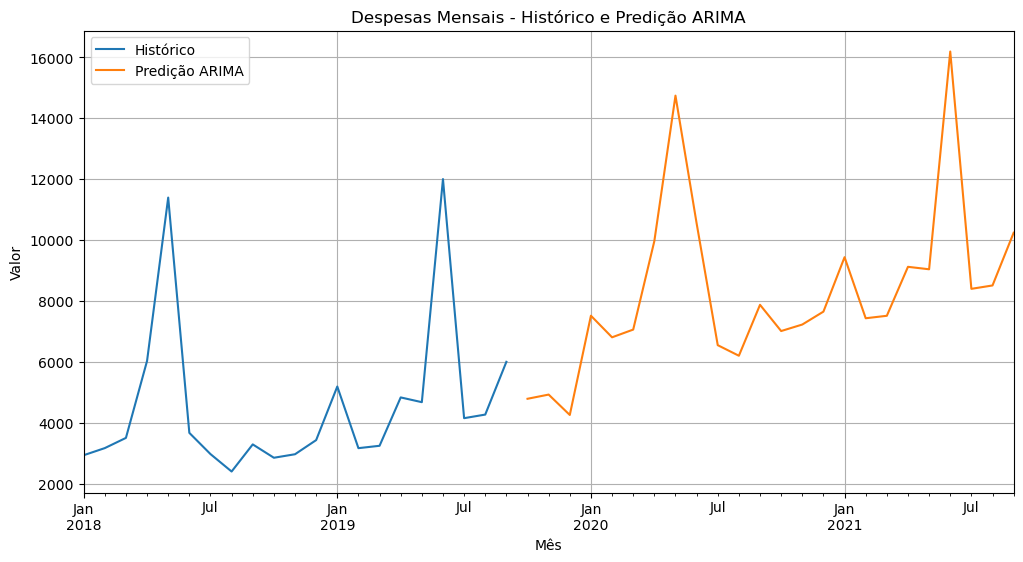

In [113]:
# Gráfico de histórico + predição do ARIMA para despesas mensais

from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt

# Agrupa despesas mensais
monthly_expenses = expenses.groupby(expenses['Date'].dt.to_period('M'))['Amount'].sum()

# Ajusta modelo ARIMA
model = SARIMAX(monthly_expenses, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
model_fit = model.fit()

# Faz predição para os próximos 24 meses
forecast = model_fit.forecast(steps=24)

# Cria eixo de datas para o forecast
forecast_index = pd.period_range(monthly_expenses.index[-1] + 1, periods=24, freq='M')
forecast.index = forecast_index

# Plota histórico + predição
plt.figure(figsize=(12, 6))
monthly_expenses.plot(label='Histórico', legend=True)
forecast.plot(label='Predição ARIMA', legend=True)
plt.title('Despesas Mensais - Histórico e Predição ARIMA')
plt.xlabel('Mês')
plt.ylabel('Valor')
plt.grid(True)
plt.show()

Já no segundo modelo ARIMA, foi notado grande similaridade com a realidade. Sendo possível utiliza-lo para a nossa análise desse caso

In [114]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

gastos_cluster = debito.groupby("Category").agg(
    valor_total=("Amount", "sum"),
    qtde_transacoes=("Amount", "count"),
    media_valor=("Amount", "mean")
).reset_index()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(gastos_cluster[["valor_total", "qtde_transacoes", "media_valor"]])


e:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

e:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

e:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.

e:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the e

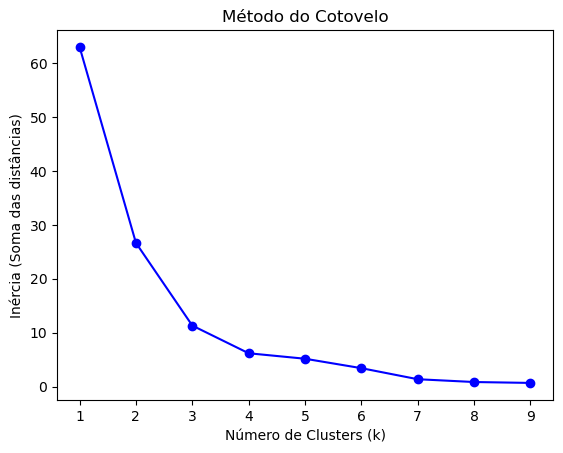

In [115]:
import matplotlib.pyplot as plt

inertia = []
K = range(1, 10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de Clusters (k)')
plt.ylabel('Inércia (Soma das distâncias)')
plt.title('Método do Cotovelo')
plt.show()


Na hora da seleção da quantidade de clusters, foi notado que após 3 clusters havia uma quebra. Sendo possível decidir entre 3 e 4 clusters

In [116]:
kmeans = KMeans(n_clusters=3, random_state=42)
gastos_cluster["cluster"] = kmeans.fit_predict(X_scaled)


e:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning:

KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.



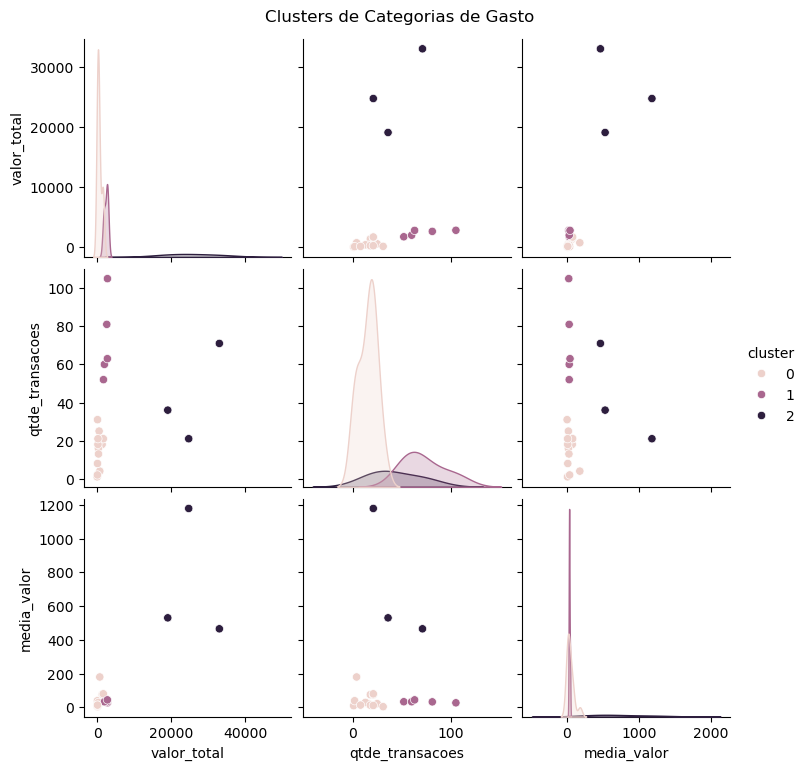

          valor_total  qtde_transacoes  media_valor
cluster                                            
0          563.262308        15.307692    43.787142
1         2374.528000        72.200000    33.763084
2        25629.576667        42.666667   724.838161


In [117]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(gastos_cluster, hue="cluster", diag_kind="kde")
plt.suptitle("Clusters de Categorias de Gasto", y=1.02)
plt.show()

perfil_clusters = gastos_cluster.groupby("cluster")[["valor_total", "qtde_transacoes", "media_valor"]].mean()
print(perfil_clusters)


Cluster 0 – Alto Valor, Baixa Frequência 
- Categorias com grandes gastos unitários, mas poucas transações (ex: Mortgage & Rent, Car Payment). 
- Representa despesas fixas e previsíveis, que drenam boa parte do orçamento mensal. 
- 💡 Recomendação: revisar contratos ou renegociar esses valores, já que têm alto impacto. 

Cluster 1 – Médio Valor, Frequência Moderada Gasto médio e número intermediário de transações (ex: Shopping, Restaurants). 
- São gastos de estilo de vida, controláveis, mas que variam mês a mês. 
- 💡 Recomendação: definir tetos de consumo mensais e monitorar variação mês a mês. 

Cluster 2 – Baixo Valor, Alta Frequência Categorias com muitos pequenos gastos, possivelmente assinaturas, cafés, transporte ou delivery
- Representam o chamado “gotejamento financeiro”.
- 💡 Recomendação: identificar quais podem ser cortados sem impacto no conforto.

In [118]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Aplicar PCA nos dados escalonados
pca = PCA(n_components=2)
pca_components = pca.fit_transform(X_scaled)

# Adicionar os componentes ao DataFrame
gastos_cluster["PCA1"] = pca_components[:, 0]
gastos_cluster["PCA2"] = pca_components[:, 1]


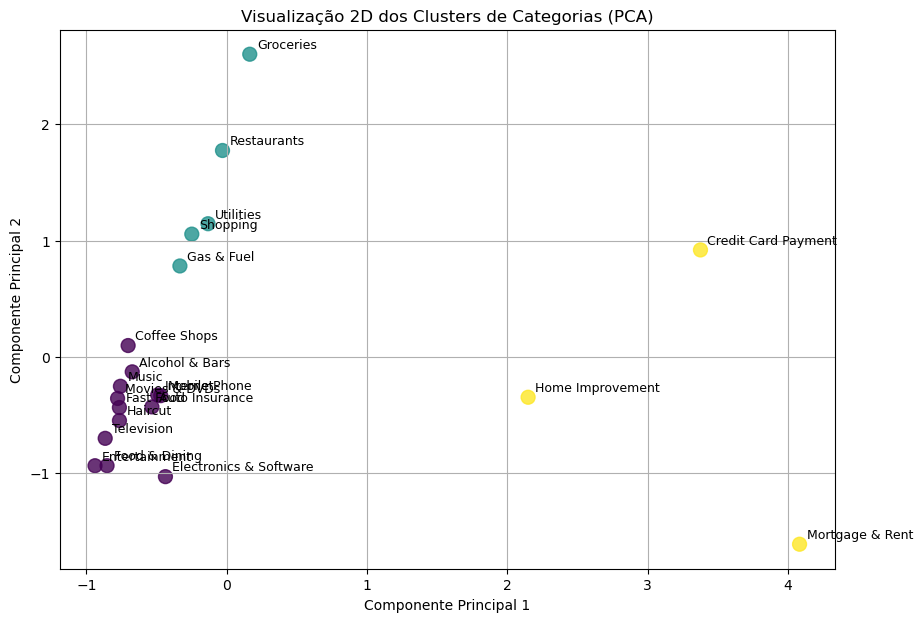

In [119]:
plt.figure(figsize=(10, 7))
plt.scatter(
    gastos_cluster["PCA1"], 
    gastos_cluster["PCA2"], 
    c=gastos_cluster["cluster"], 
    cmap="viridis", 
    s=100, alpha=0.8
)
for i, cat in enumerate(gastos_cluster["Category"]):
    plt.text(
        gastos_cluster["PCA1"][i] + 0.05, 
        gastos_cluster["PCA2"][i] + 0.05, 
        cat, fontsize=9
    )

plt.title("Visualização 2D dos Clusters de Categorias (PCA)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.grid(True)
plt.show()


Feita a análise 2D dos Clusters para identificar quais gastos estão em cada categoria de cluster

🟣 Cluster 0 — “Gastos recorrentes e de baixo impacto” Concentração alta no canto esquerdo inferior. Inclui Entertainment, Music, Television, Insurance, Internet, Electronics & Software. 
- Valores médios baixos e frequência moderada. 
- 💡 Interpretação: gastos pequenos e regulares — representam o “consumo de rotina” e lazer cotidiano. 
- 📉 Ação recomendada: revisar assinaturas e cortar redundâncias. 

🟢 Cluster 1 — “Despesas variáveis de estilo de vida” Localizado no centro-esquerda e parte superior do gráfico. Groceries, Restaurants, Shopping, Gas & Fuel, Utilities, Coffee Shops. 
- 💡 Interpretação: gastos médios, mais frequentes, ligados ao dia a dia e alimentação. 
- 📊 Ação recomendada: implementar tetos de gasto por categoria e priorizar cashback ou programas de pontos. 

🟡 Cluster 2 — “Grandes compromissos financeiros” Isolado à direita, com Mortgage & Rent, Credit Card Payment e Home Improvement. 
- 💡 Interpretação: gastos de alto valor e baixa frequência — representam compromissos fixos, muitas vezes inflexíveis. 
- 💰 Ação recomendada: revisar prazos de financiamento e buscar oportunidades de redução de juros ou renegociação.

ROAD MAP Análitico: (Ideias)
- Temporalidade: rodar K-Means por mês para ver migração de categorias entre clusters (sazonalidade/férias/Natal). 
- Novas features: % do total, desvio-padrão mensal, tendência (slope) por categoria. E
- Explainability: SHAP sobre K-Means via surrogate (e.g., árvore) para justificar fronteiras. 
- What-if: simulador de cortes (quanto cortar em B/C p/ atingir meta mensal). 
- Receitas: modelar entradas e avaliar “saldo esperado” com cenários (base/otimista/conservador).